In [1]:

print("Demand statistics:")
print(train["num_orders"].describe())

print("\nAverage orders:", train["num_orders"].mean())
print("Median orders:", train["num_orders"].median())
print("Minimum orders:", train["num_orders"].min())
print("Maximum orders:", train["num_orders"].max())

Demand statistics:


NameError: name 'train' is not defined

In [2]:
import os

print("Current folder:", os.getcwd())
print("Files available:", os.listdir())


Current folder: /Users/apple
Files available: ['Music', 'food forecast.ipynb', 'app.ipynb', 'Untitled1.ipynb', '.DS_Store', 'meal_info.csv', 'analysis.py', '.CFUserTextEncoding', 'Untitled.ipynb', '.streamlit', 'Pictures', 'test.csv', 'fulfilment_center_info.csv', '.zsh_history', 'Untitled2.ipynb', '.ipython', 'Desktop', 'Library', '.matplotlib', '.pgadmin', 'untitled.txt', 'Public', '.idlerc', 'untitled2.txt', 'Movies', 'app.py', '.Trash', 'train.csv', '.ipynb_checkpoints', '.jupyter', 'Documents', 'Downloads', '.zsh_sessions']


In [4]:
import pandas as pd
import numpy as np

train = pd.read_csv("train.csv")

print("Training data loaded successfully!")
print("Dataset shape:", train.shape)

display(train.head())


Training data loaded successfully!
Dataset shape: (423727, 9)


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1379560,1,55,1885,136.83,152.29,0,0,177
1,1466964,1,55,1993,136.83,135.83,0,0,270
2,1346989,1,55,2539,134.86,135.86,0,0,189
3,1338232,1,55,2139,339.50,437.53,0,0,54
4,1448490,1,55,2631,243.50,242.50,0,0,40


In [5]:
train = pd.read_csv("train.csv")


In [6]:
print("Demand statistics:")
print(train["num_orders"].describe())

print("\nAverage orders:", train["num_orders"].mean())
print("Median orders:", train["num_orders"].median())
print("Minimum orders:", train["num_orders"].min())
print("Maximum orders:", train["num_orders"].max())


Demand statistics:
count    423727.000000
mean        264.550536
std         403.573030
min          13.000000
25%          54.000000
50%         136.000000
75%         324.000000
max       24299.000000
Name: num_orders, dtype: float64

Average orders: 264.5505360762944
Median orders: 136.0
Minimum orders: 13
Maximum orders: 24299


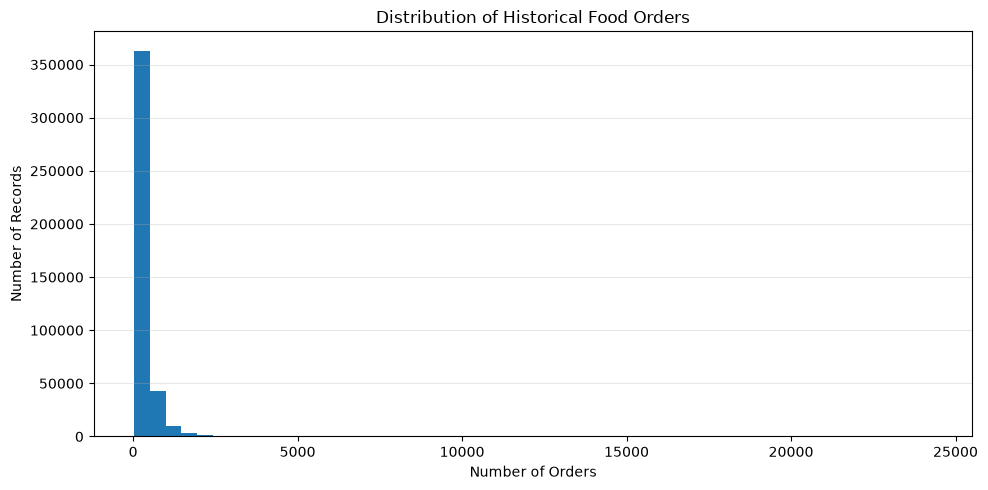

In [7]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(train["num_orders"], bins=50)

plt.title("Distribution of Historical Food Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Records")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


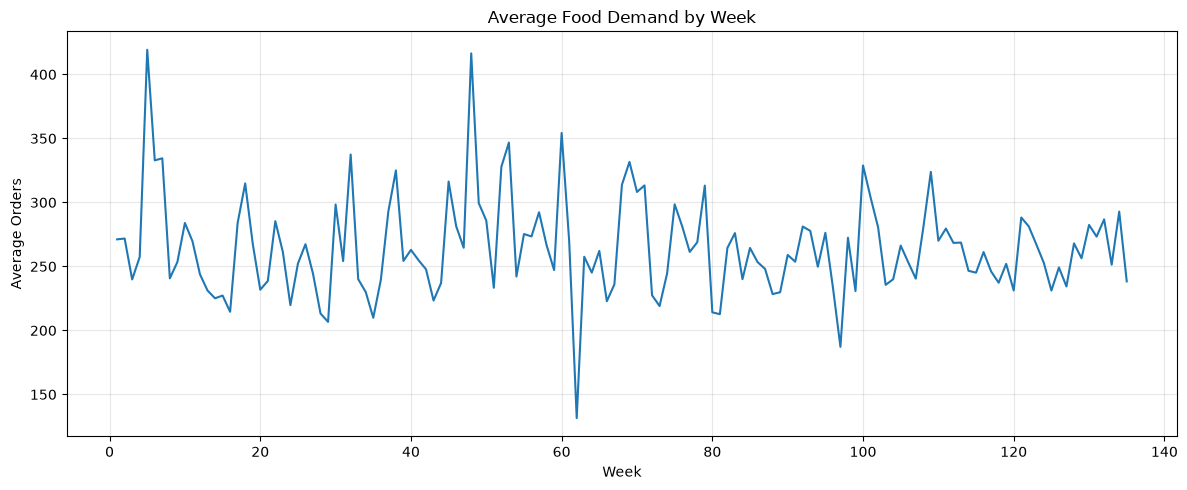

In [8]:

weekly_demand = (
    train.groupby("week")["num_orders"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(weekly_demand.index, weekly_demand.values)

plt.title("Average Food Demand by Week")
plt.xlabel("Week")
plt.ylabel("Average Orders")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [9]:

# Count missing values in each column
missing_values = train.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())


Missing values in each column:
id                       0
week                     0
center_id                0
meal_id                  0
checkout_price           0
base_price               0
emailer_for_promotion    0
homepage_featured        0
num_orders               0
dtype: int64

Total missing values: 0


In [10]:

# Count completely duplicated rows
duplicate_count = train.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Check whether the record IDs are unique
print("Number of duplicate IDs:", train["id"].duplicated().sum())


Number of duplicate rows: 0
Number of duplicate IDs: 0


In [11]:

print("Orders less than zero:",
      (train["num_orders"] < 0).sum())

print("Orders equal to zero:",
      (train["num_orders"] == 0).sum())

print("Checkout prices less than or equal to zero:",
      (train["checkout_price"] <= 0).sum())

print("Base prices less than or equal to zero:",
      (train["base_price"] <= 0).sum())


Orders less than zero: 0
Orders equal to zero: 0
Checkout prices less than or equal to zero: 0
Base prices less than or equal to zero: 0


In [12]:

import pandas as pd

meal_info = pd.read_csv("meal_info.csv")
center_info = pd.read_csv("fulfilment_center_info.csv")

print("Meal information:")
display(meal_info.head())

print("Fulfilment center information:")
display(center_info.head())


Meal information:


,meal_id,category,cuisine
0,1885,Beverages,Thai
1,1993,Beverages,Thai
2,2539,Beverages,Thai
3,1248,Beverages,Indian
4,2631,Beverages,Indian


Fulfilment center information:


,id,city_code,region_code,type,op_area
0,11,679,56,TYPE_A,3.7
1,13,590,56,TYPE_B,6.7
2,124,590,56,TYPE_C,4.0
3,66,648,34,TYPE_A,4.1
4,94,632,34,TYPE_C,3.6


In [13]:

print("Training columns:")
print(train.columns.tolist())

print("\nMeal information columns:")
print(meal_info.columns.tolist())

print("\nCenter information columns:")
print(center_info.columns.tolist())


Training columns:
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders']

Meal information columns:
['meal_id', 'category', 'cuisine']

Center information columns:
['id', 'city_code', 'region_code', 'type', 'op_area']


In [14]:

# Combine historical orders with meal information
train_merged = train.merge(
    meal_info,
    on="meal_id",
    how="left",
    validate="many_to_one"
)

# Add fulfilment center information
train_merged = train_merged.merge(
    center_info,
    on="center_id",
    how="left",
    validate="many_to_one"
)

print("Original training shape:", train.shape)
print("Merged training shape:", train_merged.shape)

display(train_merged.head())

KeyError: 'center_id'

In [15]:

print("Training dataset columns:")
print(train.columns.tolist())

print("\nMerged dataset columns:")
print(train_merged.columns.tolist())

print("\nFulfilment center dataset columns:")
print(center_info.columns.tolist())


Training dataset columns:
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders']

Merged dataset columns:
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders', 'category', 'cuisine']

Fulfilment center dataset columns:
['id', 'city_code', 'region_code', 'type', 'op_area']


In [16]:
['center_id', 'city_code', 'region_code',
 'center_type', 'op_area']

['center_id', 'city_code', 'region_code', 'center_type', 'op_area']

In [17]:

# Clean column names in all datasets
train.columns = train.columns.str.strip().str.lower()
meal_info.columns = meal_info.columns.str.strip().str.lower()
center_info.columns = center_info.columns.str.strip().str.lower()

# Check again
print("Center information columns:")
print(center_info.columns.tolist())

Center information columns:
['id', 'city_code', 'region_code', 'type', 'op_area']


In [18]:

# Merge training data with meal information
train_merged = train.merge(
    meal_info,
    on="meal_id",
    how="left",
    validate="many_to_one"
)

# Merge with fulfilment center information
train_merged = train_merged.merge(
    center_info,
    on="center_id",
    how="left",
    validate="many_to_one"
)

print("Original training rows:", len(train))
print("Merged training rows:", len(train_merged))
print("Merged columns:", train_merged.columns.tolist())

display(train_merged.head())

KeyError: 'center_id'

In [19]:
print("1. train columns:")
print(train.columns.tolist())

print("\n2. meal_info columns:")
print(meal_info.columns.tolist())

print("\n3. center_info columns:")
print(center_info.columns.tolist())

1. train columns:
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders']

2. meal_info columns:
['meal_id', 'category', 'cuisine']

3. center_info columns:
['id', 'city_code', 'region_code', 'type', 'op_area']


In [20]:

print("TRAIN columns:")
print(train.columns.tolist())

print("\nMEAL_INFO columns:")
print(meal_info.columns.tolist())

print("\nCENTER_INFO columns:")
print(center_info.columns.tolist())

TRAIN columns:
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders']

MEAL_INFO columns:
['meal_id', 'category', 'cuisine']

CENTER_INFO columns:
['id', 'city_code', 'region_code', 'type', 'op_area']


In [21]:

# Merge training data with meal information
train_merged = train.merge(
    meal_info,
    on="meal_id",
    how="left",
    validate="many_to_one"
)

# Merge with center information
# center_info uses "id", so match it with "center_id"
train_merged = train_merged.merge(
    center_info,
    left_on="center_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

# Check the result
print("Original training rows:", len(train))
print("Merged training rows:", len(train_merged))
print("\nMerged dataset columns:")
print(train_merged.columns.tolist())

display(train_merged.head())

Original training rows: 423727
Merged training rows: 423727

Merged dataset columns:
['id_x', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders', 'category', 'cuisine', 'id_y', 'city_code', 'region_code', 'type', 'op_area']


,id_x,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,category,cuisine,id_y,city_code,region_code,type,op_area
0,1379560,1,55,1885,136.83,152.29,0,0,177,Beverages,Thai,55,647,56,TYPE_C,2.0
1,1466964,1,55,1993,136.83,135.83,0,0,270,Beverages,Thai,55,647,56,TYPE_C,2.0
2,1346989,1,55,2539,134.86,135.86,0,0,189,Beverages,Thai,55,647,56,TYPE_C,2.0
3,1338232,1,55,2139,339.50,437.53,0,0,54,Beverages,Indian,55,647,56,TYPE_C,2.0
4,1448490,1,55,2631,243.50,242.50,0,0,40,Beverages,Indian,55,647,56,TYPE_C,2.0


In [22]:

# Rename confusing ID columns
train_merged = train_merged.rename(columns={
    "id_x": "record_id",
    "id_y": "center_info_id"
})

# Check the updated columns
print(train_merged.columns.tolist())

# Display the first five rows
display(train_merged.head())

['record_id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders', 'category', 'cuisine', 'center_info_id', 'city_code', 'region_code', 'type', 'op_area']


,record_id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,category,cuisine,center_info_id,city_code,region_code,type,op_area
0,1379560,1,55,1885,136.83,152.29,0,0,177,Beverages,Thai,55,647,56,TYPE_C,2.0
1,1466964,1,55,1993,136.83,135.83,0,0,270,Beverages,Thai,55,647,56,TYPE_C,2.0
2,1346989,1,55,2539,134.86,135.86,0,0,189,Beverages,Thai,55,647,56,TYPE_C,2.0
3,1338232,1,55,2139,339.50,437.53,0,0,54,Beverages,Indian,55,647,56,TYPE_C,2.0
4,1448490,1,55,2631,243.50,242.50,0,0,40,Beverages,Indian,55,647,56,TYPE_C,2.0


In [23]:

# Create new features
train_merged["price_difference"] = (
    train_merged["base_price"] - train_merged["checkout_price"]
)

train_merged["discount_percentage"] = (
    train_merged["price_difference"]
    / train_merged["base_price"].replace(0, float("nan"))
) * 100

train_merged["is_discounted"] = (
    train_merged["checkout_price"] < train_merged["base_price"]
).astype(int)

# Display the new features
display(
    train_merged[
        [
            "week",
            "checkout_price",
            "base_price",
            "price_difference",
            "discount_percentage",
            "is_discounted",
            "num_orders"
        ]
    ].head(25)
)

,week,checkout_price,base_price,price_difference,discount_percentage,is_discounted,num_orders
0,1,136.83,152.29,15.46,10.151684,1,177
1,1,136.83,135.83,-1.00,-0.736214,0,270
2,1,134.86,135.86,1.00,0.736052,1,189
3,1,339.50,437.53,98.03,22.405321,1,54
4,1,243.50,242.50,-1.00,-0.412371,0,40
5,1,251.23,252.23,1.00,0.396464,1,28
6,1,183.36,184.36,1.00,0.542417,1,190
7,1,182.36,183.36,1.00,0.545375,1,391
8,1,193.06,192.06,-1.00,-0.520671,0,472
9,1,325.92,384.18,58.26,15.164767,1,676


In [24]:

print("Dataset shape:", train_merged.shape)

print("\nMissing values in new features:")
print(
    train_merged[
        ["price_difference", "discount_percentage", "is_discounted"]
    ].isnull().sum()
)

print("\nDemand statistics:")
print(train_merged["num_orders"].describe())

Dataset shape: (423727, 19)

Missing values in new features:
price_difference       0
discount_percentage    0
is_discounted          0
dtype: int64

Demand statistics:
count    423727.000000
mean        264.550536
std         403.573030
min          13.000000
25%          54.000000
50%         136.000000
75%         324.000000
max       24299.000000
Name: num_orders, dtype: float64


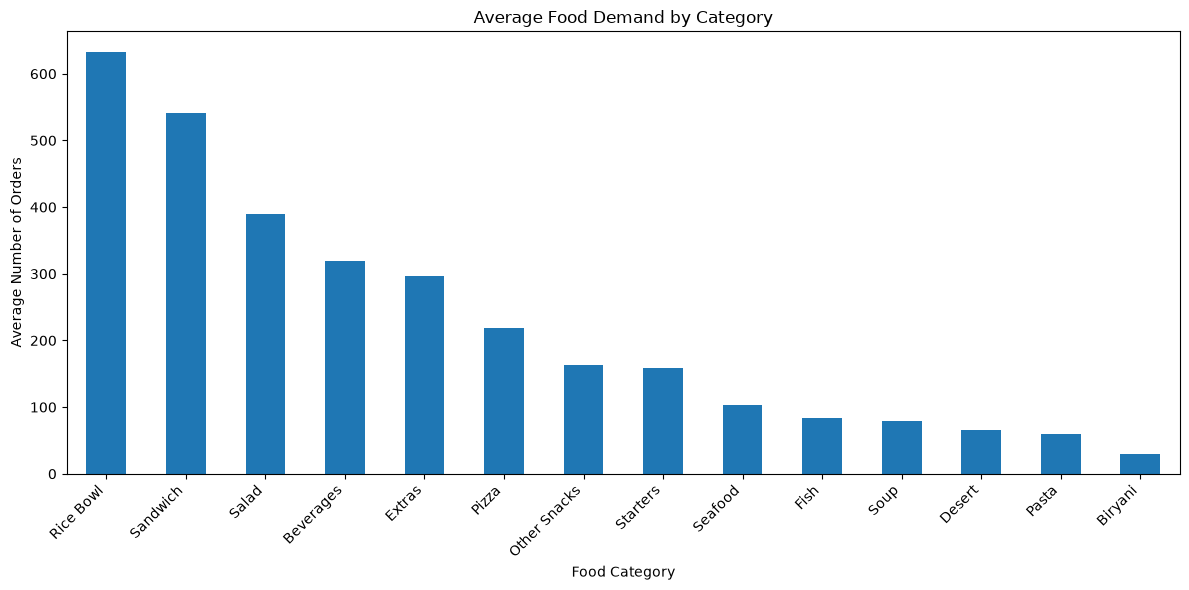

category
Rice Bowl       632.016882
Sandwich        540.797224
Salad           389.736790
Beverages       318.957959
Extras          296.000875
Pizza           219.228626
Other Snacks    162.944876
Starters        159.113247
Seafood         103.313863
Fish             83.260579
Soup             79.719401
Desert           65.458603
Pasta            59.070408
Biryani          30.364031
Name: num_orders, dtype: float64

In [25]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average demand by category
category_demand = (
    train_merged.groupby("category")["num_orders"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
category_demand.plot(kind="bar")
plt.title("Average Food Demand by Category")
plt.xlabel("Food Category")
plt.ylabel("Average Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(category_demand)

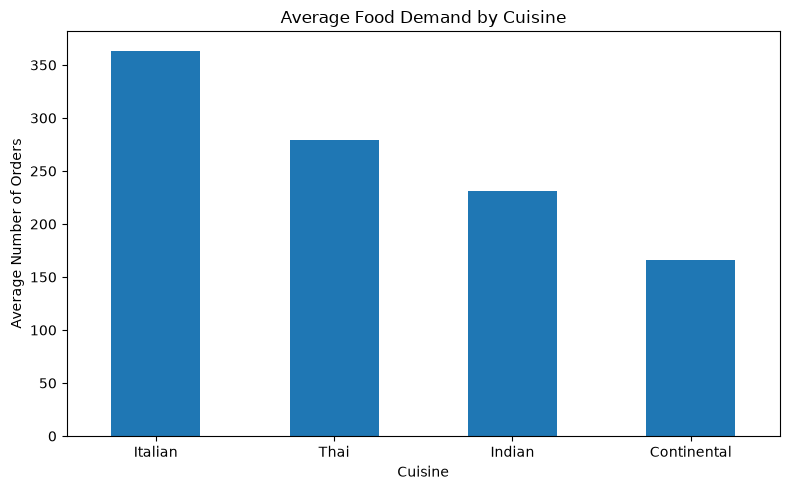

cuisine
Italian        363.571434
Thai           279.056359
Indian         231.223009
Continental    165.730078
Name: num_orders, dtype: float64

In [26]:

cuisine_demand = (
    train_merged.groupby("cuisine")["num_orders"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
cuisine_demand.plot(kind="bar")
plt.title("Average Food Demand by Cuisine")
plt.xlabel("Cuisine")
plt.ylabel("Average Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(cuisine_demand)

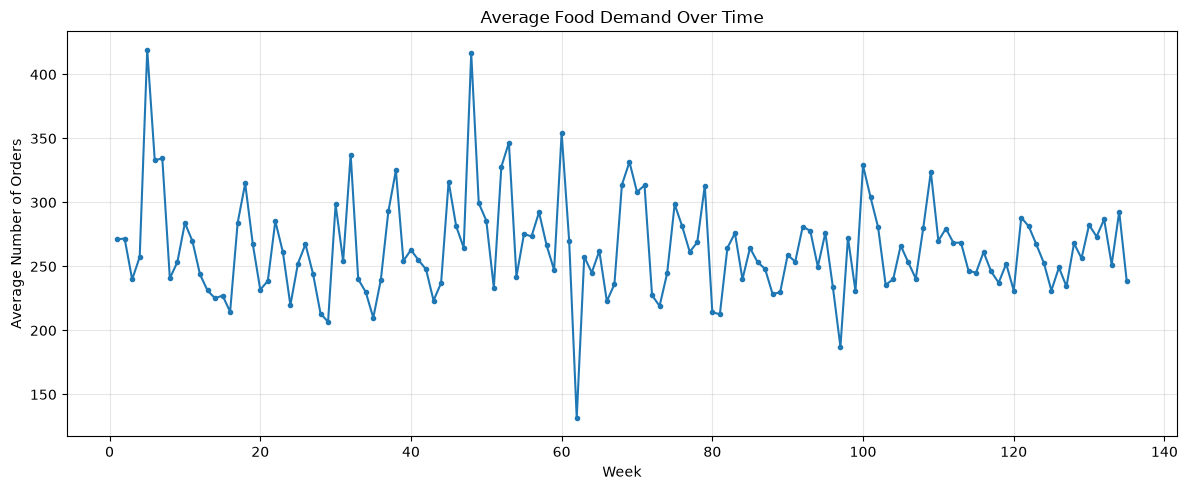

In [29]:

weekly_demand = (
    train_merged.groupby("week")["num_orders"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 5))
weekly_demand.plot(kind="line", marker="o", markersize=3)
plt.title("Average Food Demand Over Time")
plt.xlabel("Week")
plt.ylabel("Average Number of Orders")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Work on a copy
model_data = train_merged.copy()

# Select features available in the merged dataset
features = [
    "week",
    "center_id",
    "meal_id",
    "checkout_price",
    "base_price",
    "emailer_for_promotion",
    "homepage_featured",
    "category",
    "cuisine",
    "city_code",
    "region_code",
    "type",
    "op_area",
    "price_difference",
    "discount_percentage",
    "is_discounted"
]

target = "num_orders"

X = model_data[features]
y = model_data[target]

# Treat categories and IDs as categorical variables
categorical_features = [
    "center_id", "meal_id", "category", "cuisine",
    "city_code", "region_code", "type"
]

numeric_features = [
    col for col in features
    if col not in categorical_features
]

print("Feature rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target:", target)

Feature rows: 423727
Number of features: 16
Target: num_orders


In [31]:

# Sort weeks and hold out the latest 20% of weeks
weeks = np.sort(model_data["week"].unique())
split_index = int(len(weeks) * 0.8)
cutoff_week = weeks[split_index]

train_mask = model_data["week"] < cutoff_week
test_mask = model_data["week"] >= cutoff_week

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]
y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

# Preprocess numeric and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "categorical",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

# Start with a manageable Random Forest
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Last training week:", model_data.loc[train_mask, "week"].max())
print("First testing week:", model_data.loc[test_mask, "week"].min())

model.fit(X_train, y_train)

print("Model training completed!")

Training rows: 335215
Testing rows: 88512
Last training week: 108
First testing week: 109
Model training completed!


In [35]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 100.93
Root Mean Squared Error (RMSE): 211.34
R² Score: 0.7087


,Actual Orders,Predicted Orders
335215,244,218.134066
335216,202,283.579347
335217,215,205.516264
335218,14,34.178027
335219,109,79.110283
335220,27,38.538378
335221,433,213.857446
335222,298,194.063545
335223,204,197.492530
335224,28,59.402444


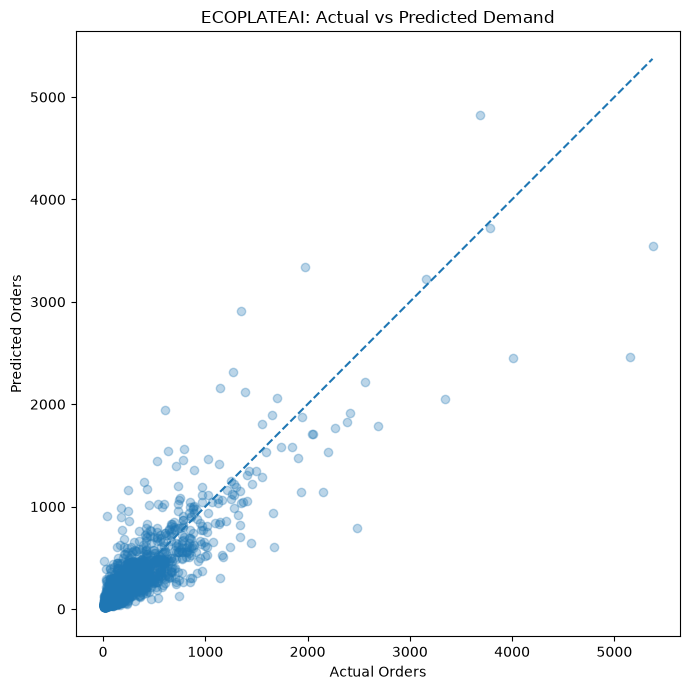

In [40]:

results = pd.DataFrame({
    "Actual Orders": y_test,
    "Predicted Orders": predictions
})

display(results.head(10))

sample = results.sample(
    n=min(2000, len(results)),
    random_state=42
)

plt.figure(figsize=(7, 7))
plt.scatter(
    sample["Actual Orders"],
    sample["Predicted Orders"],
    alpha=0.3
)

max_value = max(
    sample["Actual Orders"].max(),
    sample["Predicted Orders"].max()
)

plt.plot([0, max_value], [0, max_value], linestyle="--")
plt.xlabel("Actual Orders")
plt.ylabel("Predicted Orders")
plt.title("ECOPLATEAI: Actual vs Predicted Demand")
plt.tight_layout()
plt.show()

In [42]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Use the predictions you already generated
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("ECO PLATE AI - MODEL PERFORMANCE")
print("-" * 40)
print(f"Mean Absolute Error (MAE): {mae:.2f} orders")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} orders")
print(f"R² Score: {r2:.4f}")

ECO PLATE AI - MODEL PERFORMANCE
----------------------------------------
Mean Absolute Error (MAE): 100.93 orders
Root Mean Squared Error (RMSE): 211.34 orders
R² Score: 0.7087


In [43]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Simple baseline: predict average training demand for every test row
baseline_predictions = np.full(
    len(y_test),
    y_train.mean()
)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)
baseline_r2 = r2_score(y_test, baseline_predictions)

print("BASELINE MODEL")
print("-" * 35)
print(f"MAE:  {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")
print(f"R²:   {baseline_r2:.4f}")

print("\nRANDOM FOREST MODEL")
print("-" * 35)
print(f"MAE:  {mean_absolute_error(y_test, predictions):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predictions)):.2f}")
print(f"R²:   {r2_score(y_test, predictions):.4f}")

BASELINE MODEL
-----------------------------------
MAE:  231.02
RMSE: 391.57
R²:   -0.0000

RANDOM FOREST MODEL
-----------------------------------
MAE:  100.93
RMSE: 211.34
R²:   0.7087


TOP 15 FEATURES IN ECO PLATE AI


,Feature,Importance
1,numeric__checkout_price,0.138524
5,numeric__op_area,0.112562
4,numeric__homepage_featured,0.103610
116,categorical__meal_id_2290,0.092294
145,categorical__category_Rice Bowl,0.061850
0,numeric__week,0.050474
2,numeric__base_price,0.049224
147,categorical__category_Sandwich,0.047132
3,numeric__emailer_for_promotion,0.043327
7,numeric__discount_percentage,0.041361


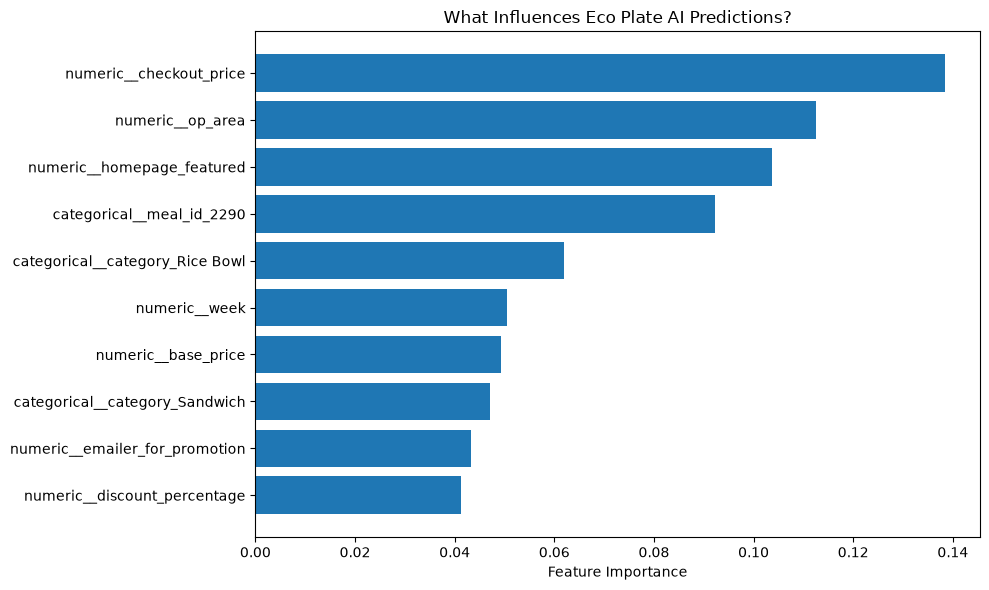

In [44]:

# Extract feature names after preprocessing
preprocessor = model.named_steps["preprocessor"]
regressor = model.named_steps["regressor"]

feature_names = preprocessor.get_feature_names_out()
importance = regressor.feature_importances_

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    })
    .sort_values("Importance", ascending=False)
)

print("TOP 15 FEATURES IN ECO PLATE AI")
display(feature_importance.head(15))

# Plot the top 10 features
top_features = feature_importance.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("What Influences Eco Plate AI Predictions?")
plt.tight_layout()
plt.show()

In [45]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Summarize demand by meal and food category
meal_summary = (
    train_merged.groupby(
        ["meal_id", "category", "cuisine"],
        as_index=False
    )
    .agg(
        average_orders=("num_orders", "mean"),
        total_orders=("num_orders", "sum"),
        records=("num_orders", "count")
    )
    .sort_values("average_orders", ascending=False)
)

print("ECO PLATE AI - DEMAND SUMMARY")
print("=" * 40)
print("Unique meals:", train_merged["meal_id"].nunique())
print("Food categories:", train_merged["category"].nunique())
print("Cuisines:", train_merged["cuisine"].nunique())

display(meal_summary.head(10))

ECO PLATE AI - DEMAND SUMMARY
Unique meals: 51
Food categories: 14
Cuisines: 4


,meal_id,category,cuisine,average_orders,total_orders,records
30,2290,Rice Bowl,Indian,896.096451,9290728,10368
22,1885,Beverages,Thai,754.952436,7793374,10323
16,1754,Sandwich,Italian,619.107605,6415193,10362
26,1993,Beverages,Thai,605.895515,6268595,10346
1,1109,Rice Bowl,Indian,575.435353,5963812,10364
25,1971,Sandwich,Italian,538.609810,5567071,10336
46,2707,Beverages,Italian,536.535594,5554753,10353
48,2826,Sandwich,Italian,464.113736,4774338,10287
15,1727,Rice Bowl,Indian,424.456975,4399921,10366
0,1062,Beverages,Italian,422.568631,4380769,10367


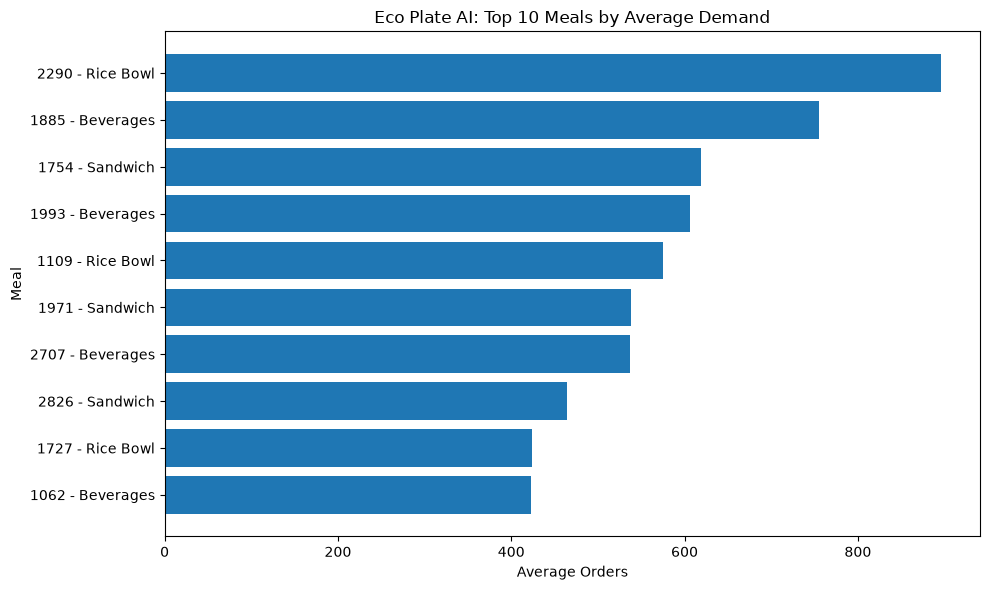

In [46]:

top_meals = meal_summary.head(10).copy()

top_meals["meal_label"] = (
    top_meals["meal_id"].astype(str)
    + " - "
    + top_meals["category"].astype(str)
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_meals["meal_label"].iloc[::-1],
    top_meals["average_orders"].iloc[::-1]
)
plt.xlabel("Average Orders")
plt.ylabel("Meal")
plt.title("Eco Plate AI: Top 10 Meals by Average Demand")
plt.tight_layout()
plt.show()

In [47]:

meal_variability = (
    train_merged.groupby(["meal_id", "category", "cuisine"])
    ["num_orders"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

meal_variability = meal_variability.rename(columns={
    "mean": "average_orders",
    "std": "demand_std_dev",
    "count": "records"
})

meal_variability = meal_variability.sort_values(
    "demand_std_dev",
    ascending=False
)

print("Meals with the most variable demand:")
display(meal_variability.head(10))

Meals with the most variable demand:


,meal_id,category,cuisine,average_orders,demand_std_dev,records
30,2290,Rice Bowl,Indian,896.096451,1040.215376,10368
25,1971,Sandwich,Italian,538.609810,767.172480,10336
16,1754,Sandwich,Italian,619.107605,738.720262,10362
22,1885,Beverages,Thai,754.952436,633.371217,10323
1,1109,Rice Bowl,Indian,575.435353,536.604168,10364
35,2490,Salad,Italian,412.132122,524.765692,8477
15,1727,Rice Bowl,Indian,424.456975,516.602001,10366
26,1993,Beverages,Thai,605.895515,462.151283,10346
46,2707,Beverages,Italian,536.535594,459.424651,10353
48,2826,Sandwich,Italian,464.113736,394.372485,10287


In [48]:

%pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 988.3 kB/s  0:00:02ta 0:00:010m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ipywidgets]3 [ipywidgets]

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


,Metric,Value
0,Observed total orders,"777,106"
1,Average orders per record,238.3
2,Unique meals,51
3,AI-estimated total orders,"797,615"


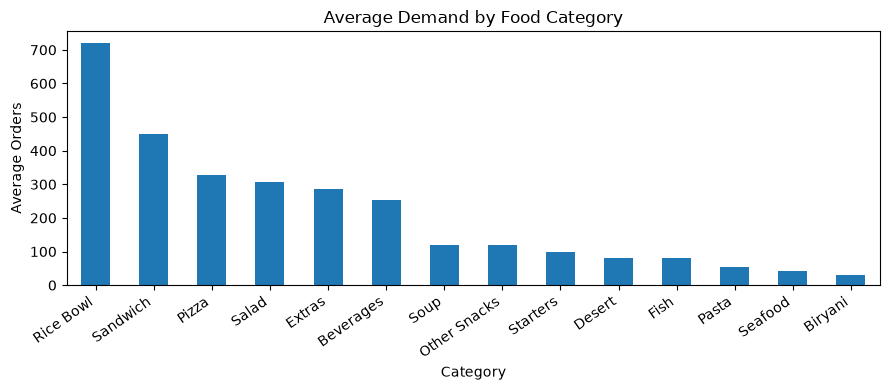

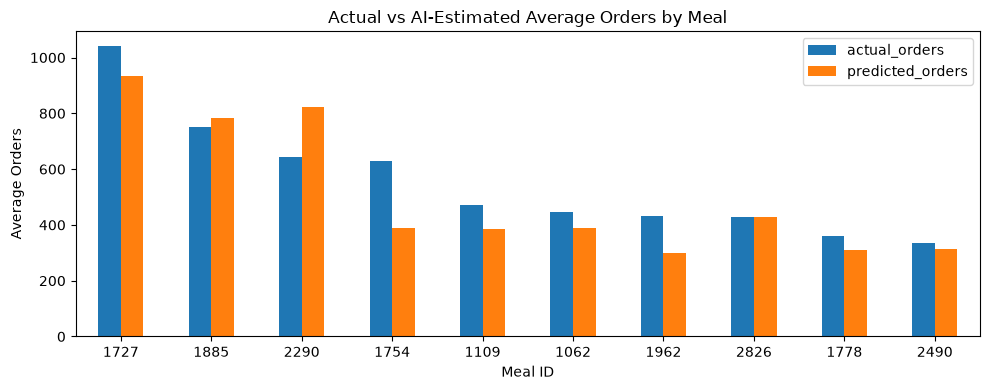

,actual_orders,predicted_orders
meal_id,,
1727,1041.9,932.2
1885,751.3,783.8
2290,642.6,821.7
1754,630.6,390.6
1109,473.0,385.4
1062,445.4,389.4
1962,432.6,300.0
2826,427.4,428.8
1778,360.2,311.0


Note: These are estimates for the selected historical week, not a validated forecast for a future week.
Order counts alone cannot measure food waste. Preparation and leftover data would be needed.


In [52]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output, HTML

# Features used by the trained model
dashboard_features = features

# Dropdown options
all_categories = ["All Categories"] + sorted(
    train_merged["category"].dropna().unique().tolist()
)
all_cuisines = ["All Cuisines"] + sorted(
    train_merged["cuisine"].dropna().unique().tolist()
)
all_weeks = sorted(train_merged["week"].dropna().unique().tolist())

# Create interactive controls
category_dropdown = widgets.Dropdown(
    options=all_categories,
    value="All Categories",
    description="Category:",
    layout=widgets.Layout(width="350px")
)

cuisine_dropdown = widgets.Dropdown(
    options=all_cuisines,
    value="All Cuisines",
    description="Cuisine:",
    layout=widgets.Layout(width="350px")
)

week_dropdown = widgets.Dropdown(
    options=all_weeks,
    value=all_weeks[-1],
    description="Week:",
    layout=widgets.Layout(width="350px")
)

dashboard_output = widgets.Output()

def update_dashboard(change=None):
    with dashboard_output:
        clear_output(wait=True)

        # Filter the selected week
        data = train_merged[
            train_merged["week"] == week_dropdown.value
        ].copy()

        if category_dropdown.value != "All Categories":
            data = data[
                data["category"] == category_dropdown.value
            ]

        if cuisine_dropdown.value != "All Cuisines":
            data = data[
                data["cuisine"] == cuisine_dropdown.value
            ]

        if data.empty:
            print("No records match these filters.")
            return

        # Summarize observed demand
        total_orders = data["num_orders"].sum()
        average_orders = data["num_orders"].mean()
        meal_count = data["meal_id"].nunique()

        # Predict demand for the selected records
        predicted = model.predict(data[dashboard_features])
        estimated_total = predicted.sum()

        # Dashboard heading and summary
        display(HTML("""
        <h1 style="color:#556B2F;">🌿 Eco Plate AI</h1>
        <h2 TAGLINE-Transforming cafeteria demand data into zero-waste culinary precision /h2>
        <p>AI-powered food demand and preparation insights</p>
        
        """))

        summary = pd.DataFrame({
            "Metric": [
                "Observed total orders",
                "Average orders per record",
                "Unique meals",
                "AI-estimated total orders"
            ],
            "Value": [
                f"{total_orders:,.0f}",
                f"{average_orders:,.1f}",
                f"{meal_count:,}",
                f"{estimated_total:,.0f}"
            ]
        })

        display(summary)

        # Demand by category
        category_summary = (
            data.groupby("category")["num_orders"]
            .mean()
            .sort_values(ascending=False)
        )

        plt.figure(figsize=(9, 4))
        category_summary.plot(kind="bar")
        plt.title("Average Demand by Food Category")
        plt.xlabel("Category")
        plt.ylabel("Average Orders")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()

        # Observed vs estimated demand by meal
        comparison = data[["meal_id", "num_orders"]].copy()
        comparison["predicted_orders"] = predicted

        comparison = comparison.groupby("meal_id").agg(
            actual_orders=("num_orders", "mean"),
            predicted_orders=("predicted_orders", "mean")
        ).sort_values("actual_orders", ascending=False).head(10)

        comparison.plot(kind="bar", figsize=(10, 4))
        plt.title("Actual vs AI-Estimated Average Orders by Meal")
        plt.xlabel("Meal ID")
        plt.ylabel("Average Orders")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

        display(comparison.round(1))

        print(
            "Note: These are estimates for the selected historical week, "
            "not a validated forecast for a future week."
        )
        print(
            "Order counts alone cannot measure food waste. "
            "Preparation and leftover data would be needed."
        )

# Connect filters to the dashboard
category_dropdown.observe(update_dashboard, names="value")
cuisine_dropdown.observe(update_dashboard, names="value")
week_dropdown.observe(update_dashboard, names="value")

# Display the dashboard
display(widgets.VBox([
    widgets.HTML("<h2>Dashboard Filters</h2>"),
    category_dropdown,
    cuisine_dropdown,
    week_dropdown,
    dashboard_output
]))

update_dashboard()

In [53]:

import ipywidgets as widgets
import pandas as pd
import numpy as np
from IPython.display import display, clear_output

# Choose a meal and a week
meal_options = sorted(train_merged["meal_id"].unique().tolist())
week_options = sorted(train_merged["week"].unique().tolist())

meal_selector = widgets.Dropdown(
    options=meal_options,
    description="Meal ID:",
    layout=widgets.Layout(width="350px")
)

week_selector = widgets.Dropdown(
    options=week_options,
    value=week_options[-1],
    description="Week:",
    layout=widgets.Layout(width="350px")
)

buffer_selector = widgets.IntSlider(
    value=10,
    min=0,
    max=30,
    step=5,
    description="Extra buffer (%):",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

planner_output = widgets.Output()

def plan_preparation(change=None):
    with planner_output:
        clear_output(wait=True)

        meal_id = meal_selector.value
        selected_week = week_selector.value

        # Find historical records for this meal
        meal_data = train_merged[
            train_merged["meal_id"] == meal_id
        ].copy()

        # Use the selected week's records as inputs
        selected_data = meal_data[
            meal_data["week"] == selected_week
        ].copy()

        if selected_data.empty:
            print("No records available for this meal and week.")
            return

        # Predict demand for each available center record
        predicted_orders = model.predict(
            selected_data[features]
        )

        # Total predicted demand across centers
        predicted_total = max(0, predicted_orders.sum())

        # Add a user-selected preparation buffer
        buffer = buffer_selector.value / 100
        preparation_target = int(np.ceil(
            predicted_total * (1 + buffer)
        ))

        meal_details = selected_data.iloc[0]

        print("🌿 ECO PLATE AI — PREPARATION PLAN")
        print("-" * 40)
        print("Meal ID:", meal_id)
        print("Category:", meal_details["category"])
        print("Cuisine:", meal_details["cuisine"])
        print("Selected week:", selected_week)
        print("Centers with records:", len(selected_data))
        print()
        print(f"AI-estimated demand: {predicted_total:,.0f} orders")
        print(f"Preparation buffer: {buffer_selector.value}%")
        print(f"Suggested quantity: {preparation_target:,} portions")
        print()
        print(
            "Important: This is an experimental planning estimate "
            "based on historical records, not a validated future forecast."
        )
        print(
            "The buffer adds extra portions and may increase waste. "
            "Choose it based on kitchen capacity, perishability, "
            "and the cost of running short."
        )

meal_selector.observe(plan_preparation, names="value")
week_selector.observe(plan_preparation, names="value")
buffer_selector.observe(plan_preparation, names="value")

display(widgets.VBox([
    widgets.HTML("<h2>🥗 Smart Preparation Planner</h2>"),
    meal_selector,
    week_selector,
    buffer_selector,
    planner_output
]))

plan_preparation()

🌿 ECO PLATE AI — PREPARATION PLAN
----------------------------------------
Meal ID: 1062
Category: Beverages
Cuisine: Italian
Selected week: 135
Centers with records: 77

AI-estimated demand: 29,986 orders
Preparation buffer: 10%
Suggested quantity: 32,985 portions

Important: This is an experimental planning estimate based on historical records, not a validated future forecast.
The buffer adds extra portions and may increase waste. Choose it based on kitchen capacity, perishability, and the cost of running short.


In [54]:

%pip install streamlit joblib


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [55]:

import os
import joblib

# Create a folder for the web app
os.makedirs("eco_plate_ai", exist_ok=True)

# Save the trained model and its feature configuration
joblib.dump(model, "eco_plate_ai/model.pkl")
joblib.dump(features, "eco_plate_ai/features.pkl")

print("Model saved:", os.path.exists("eco_plate_ai/model.pkl"))
print("Features saved:", os.path.exists("eco_plate_ai/features.pkl"))

Model saved: True
Features saved: True


In [56]:

# Save the merged dataset for use in the web app
train_merged.to_csv(
    "eco_plate_ai/train_merged.csv",
    index=False
)

print("Dataset saved successfully!")
print("Rows:", len(train_merged))
print("Columns:", len(train_merged.columns))

Dataset saved successfully!
Rows: 423727
Columns: 19


In [57]:

import os
print("Jupyter is currently working in:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Jupyter is currently working in:
/Users/apple

Files and folders here:
['Music', 'food forecast.ipynb', 'app.ipynb', 'Untitled1.ipynb', '.DS_Store', 'meal_info.csv', 'analysis.py', '.CFUserTextEncoding', 'Untitled.ipynb', '.streamlit', 'Pictures', 'test.csv', 'fulfilment_center_info.csv', '.zsh_history', 'Untitled2.ipynb', '.ipython', 'Desktop', 'Library', '.matplotlib', '.pgadmin', 'untitled.txt', 'Public', '.idlerc', 'untitled2.txt', 'Movies', 'app.py', 'eco_plate_ai', '.Trash', 'train.csv', '.ipynb_checkpoints', '.jupyter', 'Documents', 'Downloads', '.zsh_sessions']


In [58]:

project_folder = os.path.abspath("eco_plate_ai")

print("Your project folder is:")
print(project_folder)

print("\nFiles inside the folder:")
print(os.listdir(project_folder))

Your project folder is:
/Users/apple/eco_plate_ai

Files inside the folder:
['features.pkl', 'train_merged.csv', 'model.pkl']


In [59]:

import os

project_folder = os.path.abspath("eco_plate_ai")

print("Project folder:", project_folder)
print("\nFiles found:")
print(os.listdir(project_folder))

Project folder: /Users/apple/eco_plate_ai

Files found:
['features.pkl', 'train_merged.csv', 'model.pkl']


In [61]:
cd "/Users/apple/eco_plate_ai"

/Users/apple/eco_plate_ai


In [62]:
import os

project_folder = "/Users/apple/eco_plate_ai"

print("Folder exists:", os.path.exists(project_folder))

if os.path.exists(project_folder):
    print("Files inside the folder:")
    print(os.listdir(project_folder))

Folder exists: True
Files inside the folder:
['features.pkl', 'train_merged.csv', 'model.pkl']


In [64]:
import os

project_folder = "/Users/apple/eco_plate_ai"

print("Project folder exists:", os.path.exists(project_folder))

if os.path.exists(project_folder):
    print("Files:", os.listdir(project_folder))

Project folder exists: True
Files: ['features.pkl', 'train_merged.csv', 'model.pkl']


In [66]:

%%writefile /Users/apple/eco_plate_ai/app.py
import streamlit as st
import pandas as pd
import joblib
import os

st.set_page_config(
    page_title="Eco Plate AI",
    page_icon="🌱",
    layout="wide"
)

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

@st.cache_resource
def load_model():
    return joblib.load(os.path.join(BASE_DIR, "model.pkl"))

@st.cache_data
def load_data():
    return pd.read_csv(os.path.join(BASE_DIR, "train_merged.csv"))

st.title("🌱 Eco Plate AI")
st.subheader("AI-powered food demand forecasting and waste reduction")
st.caption("Predict demand. Plan preparation. Help reduce food waste.")

try:
    model = load_model()
    df = load_data()
    features = joblib.load(os.path.join(BASE_DIR, "features.pkl"))
except Exception as e:
    st.error(f"Could not load project files: {e}")
    st.info("Check that model.pkl, features.pkl, and train_merged.csv are in the project folder.")
    st.stop()

# Sidebar controls
st.sidebar.header("⚙️ Demand Planning")
categories = sorted(df["category"].dropna().unique())
category = st.sidebar.selectbox("Food category", categories)

cuisines = sorted(df["cuisine"].dropna().unique())
cuisine = st.sidebar.selectbox("Cuisine", cuisines)

centers = sorted(df["center_id"].dropna().unique())
center = st.sidebar.selectbox("Food center", centers)

weeks = sorted(df["week"].dropna().unique())
week = st.sidebar.selectbox("Historical week", weeks)

# Dashboard metrics
filtered = df[
    (df["category"] == category) &
    (df["cuisine"] == cuisine) &
    (df["center_id"] == center) &
    (df["week"] == week)
]

c1, c2, c3 = st.columns(3)
c1.metric("Historical orders", f"{int(filtered['num_orders'].sum()):,}")
c2.metric("Meals in selection", f"{len(filtered):,}")
c3.metric("Average orders per record",
          f"{filtered['num_orders'].mean():.1f}" if not filtered.empty else "N/A")

st.divider()
st.header("🔮 Demand Prediction")

if filtered.empty:
    st.warning("No matching historical records. Try another filter combination.")
else:
    # Use available historical rows as prediction examples
    X = filtered[features].copy()
    predictions = model.predict(X)
    prediction_total = max(0, int(round(predictions.sum())))

    st.metric("Estimated demand for this selection", f"{prediction_total:,} meals")
    st.caption(
        "This estimate uses records from the selected historical week. "
        "It is a model estimate, not a validated future-week forecast."
    )

    chart_df = pd.DataFrame({
        "Meal record": range(1, len(predictions) + 1),
        "Actual orders": filtered["num_orders"].values,
        "Estimated orders": predictions.round().clip(min=0)
    }).set_index("Meal record")

    st.subheader("Actual vs estimated orders")
    st.line_chart(chart_df)

    st.divider()
    st.header("🍲 Preparation Planner")
    buffer_pct = st.slider("Extra preparation buffer (%)", 0, 30, 10)
    planned = int(round(prediction_total * (1 + buffer_pct / 100)))
    st.metric("Suggested preparation quantity", f"{planned:,} meals")
    st.caption(
        "Planning suggestion only. Adjust for stock on hand, shelf life, "
        "and local operating conditions."
    )

st.divider()
st.header("📊 Dataset Overview")
st.write("Explore the historical order data used by the app.")
st.dataframe(
    df[["week", "center_id", "category", "cuisine",
        "num_orders", "checkout_price"]].head(100),
    use_container_width=True
)

st.caption("Eco Plate AI | Hackathon prototype")

Overwriting /Users/apple/eco_plate_ai/app.py


In [2]:

%%writefile /Users/apple/eco_plate_ai/app.py
import os
import joblib
import streamlit as st
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# ---------- PAGE SETTINGS ----------
st.set_page_config(
    page_title="Eco Plate AI | Smart Food Planning",
    page_icon="🌿",
    layout="wide",
    initial_sidebar_state="expanded"
)

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

# ---------- CUSTOM DESIGN ----------
st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700&family=Manrope:wght@400;500;600;700;800&display=swap');

html, body, [class*="css"] {
    font-family: 'DM Sans', sans-serif;
}
.stApp {
    background: linear-gradient(135deg, #f4faf5 0%, #edf7f2 50%, #f8fbf7 100%);
}
h1, h2, h3 {
    font-family: 'Manrope', sans-serif !important;
    color: #153e32;
}
.hero {
    padding: 34px;
    border-radius: 24px;
    background: linear-gradient(120deg, #123c30, #16745b, #32a879);
    color: white;
    margin-bottom: 25px;
    box-shadow: 0 12px 32px rgba(18, 80, 57, .18);
    animation: appear .7s ease-out;
}
.hero h1 { color: white !important; font-size: 38px; margin: 0; }
.hero p { color: #e1f7e9; font-size: 16px; margin-bottom: 0; }
.eyebrow {
    text-transform: uppercase;
    letter-spacing: 2px;
    font-size: 12px;
    font-weight: 700;
    color: #b8f3ce;
}
.metric-card {
    background: rgba(255,255,255,.94);
    border: 1px solid #dcece2;
    border-radius: 18px;
    padding: 22px;
    box-shadow: 0 5px 18px rgba(22, 70, 49, .06);
    transition: transform .22s ease, box-shadow .22s ease;
    min-height: 125px;
}
.metric-card:hover {
    transform: translateY(-5px);
    box-shadow: 0 12px 25px rgba(22, 70, 49, .12);
}
.metric-label { color: #647b70; font-size: 13px; font-weight: 600; }
.metric-value { color: #174c39; font-size: 30px; font-weight: 800; margin-top: 8px; }
.metric-icon { font-size: 22px; }
.section-card {
    background: white;
    padding: 22px;
    border: 1px solid #e1eee5;
    border-radius: 20px;
    box-shadow: 0 5px 18px rgba(22, 70, 49, .045);
}
div[data-testid="stSidebar"] {
    background: linear-gradient(180deg, #123c30, #1b5944);
}
div[data-testid="stSidebar"] * { color: #f1fff5; }
div[data-testid="stSidebar"] label { font-weight: 600; }
.stButton > button {
    background: linear-gradient(100deg, #16745b, #2aa876);
    color: white;
    border: none;
    border-radius: 12px;
    padding: 10px 20px;
    font-weight: 700;
    transition: .2s ease;
}
.stButton > button:hover {
    transform: translateY(-2px);
    box-shadow: 0 7px 16px rgba(22,116,91,.25);
    color: white;
}
div[data-testid="stDataFrame"] {
    border: 1px solid #dcece2;
    border-radius: 14px;
}
@keyframes appear {
    from { opacity: 0; transform: translateY(12px); }
    to { opacity: 1; transform: translateY(0); }
}
.footer {
    text-align: center;
    color: #688176;
    padding: 24px;
    font-size: 13px;
}
</style>
""", unsafe_allow_html=True)

# ---------- LOAD FILES ----------
@st.cache_resource
def load_model():
    return joblib.load(os.path.join(BASE_DIR, "model.pkl"))

@st.cache_data
def load_data():
    return pd.read_csv(os.path.join(BASE_DIR, "train_merged.csv"))

@st.cache_data
def load_features():
    return joblib.load(os.path.join(BASE_DIR, "features.pkl"))

try:
    model = load_model()
    df = load_data()
    features = load_features()
except Exception as e:
    st.error(f"Unable to load the project files: {e}")
    st.info("Check that model.pkl, features.pkl and train_merged.csv are in the same folder as app.py.")
    st.stop()

# ---------- HERO ----------
st.markdown("""
<div class="hero">
    <div class="eyebrow">🌎 Sustainable food intelligence</div>
    <h1>Eco Plate AI</h1>
    <p>Smarter demand planning. Better food decisions. A greener tomorrow.</p>
</div>
""", unsafe_allow_html=True)

# ---------- SIDEBAR FILTERS ----------
st.sidebar.markdown("## 🌿 Eco Plate AI")
st.sidebar.caption("YOUR FOOD PLANNING WORKSPACE")
st.sidebar.divider()
st.sidebar.markdown("### 🎛️ Choose your data")

categories = sorted(df["category"].dropna().unique().tolist())
cuisines = sorted(df["cuisine"].dropna().unique().tolist())
centers = sorted(df["center_id"].dropna().unique().tolist())
weeks = sorted(df["week"].dropna().unique().tolist())

category = st.sidebar.selectbox("Food category", categories)
cuisine = st.sidebar.selectbox("Cuisine", cuisines)
center = st.sidebar.selectbox("Food center", centers)
week = st.sidebar.selectbox("Historical week", weeks)

st.sidebar.divider()
st.sidebar.caption("Built to support smarter food preparation 🌱")

# ---------- FILTER DATA ----------
filtered = df[
    (df["category"] == category) &
    (df["cuisine"] == cuisine) &
    (df["center_id"] == center) &
    (df["week"] == week)
].copy()

# ---------- KPI CARDS ----------
st.markdown("### 📈 Your sustainability snapshot")

total_orders = int(filtered["num_orders"].sum()) if not filtered.empty else 0
record_count = len(filtered)
average_orders = filtered["num_orders"].mean() if record_count else 0
average_price = filtered["checkout_price"].mean() if record_count else 0

k1, k2, k3, k4 = st.columns(4)

def metric_card(col, icon, label, value):
    with col:
        st.markdown(f"""
        <div class="metric-card">
            <div class="metric-icon">{icon}</div>
            <div class="metric-label">{label}</div>
            <div class="metric-value">{value}</div>
        </div>
        """, unsafe_allow_html=True)

metric_card(k1, "🧾", "Historical orders", f"{total_orders:,}")
metric_card(k2, "🍽️", "Matching records", f"{record_count:,}")
metric_card(k3, "📊", "Average orders", f"{average_orders:,.1f}")
metric_card(k4, "💰", "Average checkout price", f"{average_price:,.2f}")

st.write("")

# ---------- TABS ----------
overview_tab, forecast_tab, planner_tab, data_tab = st.tabs([
    "🌿 Overview", "🔮 Demand Insights", "🍲 Preparation Planner", "📋 Explore Data"
])

with overview_tab:
    st.markdown("### 📊 Order patterns")
    if filtered.empty:
        st.warning("No records match these filters. Please change your selections.")
    else:
        left, right = st.columns(2)

        with left:
            category_data = (
                df.groupby("category", as_index=False)["num_orders"]
                .sum().sort_values("num_orders", ascending=False)
            )
            fig = px.bar(
                category_data, x="category", y="num_orders",
                title="Orders by food category",
                color="num_orders",
                color_continuous_scale=["#b9ebc9", "#38a878", "#12533d"],
                labels={"category": "Food category", "num_orders": "Orders"}
            )
            fig.update_layout(
                plot_bgcolor="white", paper_bgcolor="white",
                font_family="DM Sans", title_font_size=17,
                coloraxis_showscale=False, margin=dict(l=10, r=10, t=55, b=10)
            )
            st.plotly_chart(fig, use_container_width=True)

        with right:
            weekly = (
                df.groupby("week", as_index=False)["num_orders"]
                .sum().sort_values("week")
            )
            fig = px.area(
                weekly, x="week", y="num_orders",
                title="Historical demand trend",
                markers=True,
                color_discrete_sequence=["#16a085"],
                labels={"week": "Week", "num_orders": "Orders"}
            )
            fig.update_traces(
                fill="tozeroy",
                fillcolor="rgba(22,160,133,0.14)",
                line=dict(width=3)
            )
            fig.update_layout(
                plot_bgcolor="white", paper_bgcolor="white",
                font_family="DM Sans", title_font_size=17,
                margin=dict(l=10, r=10, t=55, b=10)
            )
            st.plotly_chart(fig, use_container_width=True)

        st.caption("These charts summarize the historical dataset, not measured food waste.")

with forecast_tab:
    st.markdown("### 🔮 Model-based demand estimate")
    st.write("Estimate orders for the selected historical records using your trained model.")

    if filtered.empty:
        st.warning("No matching records. Change the sidebar filters.")
    else:
        X = filtered[features].copy()
        predictions = model.predict(X)
        predictions = pd.Series(predictions).clip(lower=0)

        actual_total = int(filtered["num_orders"].sum())
        predicted_total = int(round(predictions.sum()))

        a, b = st.columns(2)
        metric_card(a, "🧾", "Actual historical orders", f"{actual_total:,}")
        metric_card(b, "🤖", "Model estimated orders", f"{predicted_total:,}")

        chart_df = pd.DataFrame({
            "Record": range(1, len(filtered) + 1),
            "Actual orders": filtered["num_orders"].to_numpy(),
            "Predicted orders": predictions.to_numpy()
        }).melt(
            id_vars="Record",
            var_name="Series",
            value_name="Orders"
        )

        fig = px.line(
            chart_df, x="Record", y="Orders", color="Series",
            title="Actual vs predicted orders",
            color_discrete_map={
                "Actual orders": "#1677d2",
                "Predicted orders": "#16a085"
            },
            markers=True
        )
        fig.update_layout(
            plot_bgcolor="white", paper_bgcolor="white",
            font_family="DM Sans", title_font_size=18,
            legend_title_text="", margin=dict(l=10, r=10, t=55, b=10)
        )
        st.plotly_chart(fig, use_container_width=True)

        st.info(
            "Prototype limitation: this view predicts records from the selected historical week. "
            "It is not yet a future-week forecast, and the project does not have measured food-waste data."
        )

with planner_tab:
    st.markdown("### 🍲 Smart preparation planner")
    st.write("Create a preparation estimate from the model output.")

    if filtered.empty:
        st.warning("No matching records. Change the sidebar filters.")
    else:
        predictions = pd.Series(model.predict(filtered[features])).clip(lower=0)
        base_demand = max(0, int(round(predictions.sum())))

        col1, col2 = st.columns([1, 1])

        with col1:
            buffer_pct = st.slider("Preparation buffer (%)", 0, 30, 10)
            stock = st.number_input(
                "Usable meals already available",
                min_value=0, value=0, step=10
            )

        planned_total = int(round(base_demand * (1 + buffer_pct / 100)))
        additional = max(0, planned_total - int(stock))
        surplus_risk = max(0, int(stock) - planned_total)

        with col2:
            st.markdown('<div class="section-card">', unsafe_allow_html=True)
            st.markdown("#### 🎯 Preparation recommendation")
            st.metric("Estimated demand", f"{base_demand:,} meals")
            st.metric("Planned total including buffer", f"{planned_total:,} meals")
            st.metric("Additional meals to prepare", f"{additional:,} meals")
            st.metric("Stock above planned quantity", f"{surplus_risk:,} meals")
            st.markdown('</div>', unsafe_allow_html=True)

        st.caption(
            "This is a planning aid, not a measured waste prediction. "
            "Review shelf life, existing inventory and food safety before preparing meals."
        )

with data_tab:
    st.markdown("### 📋 Historical data explorer")
    st.write(f"Showing up to 200 rows from {len(df):,} records.")
    st.dataframe(
        df[[
            "week", "center_id", "category", "cuisine",
            "checkout_price", "num_orders"
        ]].head(200),
        use_container_width=True,
        hide_index=True
    )

    csv = df.head(200).to_csv(index=False).encode("utf-8")
    st.download_button(
        "⬇️ Download sample data (CSV)",
        data=csv,
        file_name="eco_plate_sample.csv",
        mime="text/csv"
    )

st.markdown("""
<div class="footer">
    🌱 <b>Eco Plate AI</b> · Smarter food planning for a more sustainable future<br>
    <small>Hackathon prototype · Predictions are estimates, not guarantees of reduced waste.</small>
</div>
""", unsafe_allow_html=True)

Overwriting /Users/apple/eco_plate_ai/app.py


In [3]:
%pip install plotly streamlit pandas joblib scikit-learn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:

# ---------- VISUAL RISK RADAR ----------
st.markdown("---")
st.header("🚨 Food Waste & Stock-out Risk Radar")
st.caption(
    "Planning indicators based on predicted demand and preparation quantities. "
    "These scores are heuristics, not calibrated probabilities."
)

if "forecast_df" in locals() and not forecast_df.empty:
    risk_data = forecast_df.copy()

    demand_col = (
        "predicted_demand"
        if "predicted_demand" in risk_data.columns
        else "forecast"
    )

    if demand_col in risk_data.columns:
        item_options = risk_data["item"].astype(str).tolist()
        selected_item = st.selectbox(
            "Select menu item for risk analysis",
            item_options,
            key="risk_radar_item"
        )

        row = risk_data[
            risk_data["item"].astype(str) == selected_item
        ].iloc[0]

        demand = max(0, float(row[demand_col]))

        prep_col = next(
            (c for c in ["recommended_prep", "prepared", "prep_quantity"]
             if c in risk_data.columns),
            None
        )

        prep = (
            max(0, float(row[prep_col]))
            if prep_col
            else demand
        )

        stock = st.number_input(
            "Current available portions",
            min_value=0,
            value=int(round(prep)),
            step=1,
            key="risk_radar_stock"
        )

        waste_risk = min(
            100,
            max(0, round((prep - demand) / max(prep, 1) * 100))
        )

        stockout_risk = min(
            100,
            max(0, round((demand - stock) / max(demand, 1) * 100))
        )

        surplus_risk = min(
            100,
            max(0, round((stock - demand) / max(stock, 1) * 100))
        )

        demand_spike = min(
            100,
            max(0, round((demand - prep) / max(demand, 1) * 100))
        )

        categories = [
            "Waste risk",
            "Stock-out risk",
            "Surplus stock",
            "Demand spike"
        ]

        scores = [
            waste_risk,
            stockout_risk,
            surplus_risk,
            demand_spike
        ]

        fig = go.Figure()

        fig.add_trace(go.Scatterpolar(
            r=scores + [scores[0]],
            theta=categories + [categories[0]],
            fill="toself",
            name=selected_item,
            line=dict(color="#159570", width=3),
            fillcolor="rgba(21,149,112,0.22)"
        ))

        fig.update_layout(
            polar=dict(
                radialaxis=dict(
                    visible=True,
                    range=[0, 100],
                    ticksuffix="%",
                )
            ),
            showlegend=False,
            height=480,
            margin=dict(l=50, r=50, t=35, b=35),
            paper_bgcolor="rgba(0,0,0,0)",
            font=dict(color="#153e32")
        )

        left, right = st.columns(2)
        left.plotly_chart(fig, use_container_width=True)

        with right:
            st.subheader("Risk summary")

            st.metric("Waste risk", f"{waste_risk}%")
            st.metric("Stock-out risk", f"{stockout_risk}%")

            if stockout_risk >= 50:
                st.error("High stock-out risk: available portions may not meet demand.")
            elif waste_risk >= 40:
                st.warning("Potential surplus: consider reducing preparation.")
            else:
                st.success("No high heuristic risk detected.")

            st.caption(
                "These indicators are simplified planning estimates, "
                "not measured waste or validated probability estimates."
            )
    else:
        st.warning("Could not find a demand column in the forecast data.")
else:
    st.info(
        "Generate your forecast first. The risk radar uses the forecast "
        "DataFrame already created by your app."
    )

NameError: name 'st' is not defined